# Four-Station Control

Control experiment isolating **sample size** from **feature-space coverage** in the
AWS-only ($f = 0$) configuration of the land use regression (see the `lur-model` notebook).

With four stations the standardized predictor matrix has rank three, so at most three
predictors can enter the model regardless of where those stations are sited: the
parsimony of the AWS-only fit is imposed by the sample size, not by the environmental
range the stations span. What the sample size does *not* determine is **which**
predictors are retained, and with which sign.

To separate the two, we repeat the AWS-only selection on random four-station subsets of
the LCS network. These share the same rank ceiling and differ only in siting, so any
difference in the retained predictors is attributable to coverage alone.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from zurich_uhi_lur import regr_utils
from zurich_uhi_lur.regr_utils import SpearmanVIFSelector

sns.set_theme(style="ticks")

In [2]:
# input data paths
stations_gdf_filepath = "../data/processed/stations.gpkg"
station_features_filepath = "../data/processed/stations-features.csv"
ts_df_filepath = "../data/processed/ts-df.csv"

# output
dst_control_filepath = "../data/processed/lur-nfour-control.csv"

# experiment settings (must match lur-model)
# hour of the day (local time)
target_hour = 23
seed = 0
vif_threshold = 5.0

# control settings
n_stations = 4  # matches the number of AWS
n_draws = 200

In [3]:
# Parameters
stations_gdf_filepath = "data/processed/stations.gpkg"
station_features_filepath = "data/processed/stations-features.csv"
ts_df_filepath = "data/processed/ts-df.csv"
dst_control_filepath = "data/processed/lur-nfour-control.csv"


## Data loading

In [4]:
station_features_gdf = regr_utils.get_site_features_gdf(
    station_features_filepath, stations_gdf_filepath
)
# Station 534 is co-located with Zürich-Kaserne (identical features), excluded in
# lur-model and therefore excluded here as well.
station_features_gdf = station_features_gdf[station_features_gdf.index != "534"]
aws_gdf = station_features_gdf[station_features_gdf["source"] == "AWS"]
lcs_gdf = station_features_gdf[station_features_gdf["source"] == "LCS"]

feature_columns = station_features_gdf.columns.drop(["geometry", "source"])
print(f"{len(aws_gdf)} AWS, {len(lcs_gdf)} LCS, {len(feature_columns)} predictors")

4 AWS, 117 LCS, 14 predictors


In [5]:
ts_df = (
    pd.read_csv(ts_df_filepath, index_col=["heatwave", "time"], parse_dates=["time"])
    .rename_axis(columns=station_features_gdf.index.name)
    .droplevel("heatwave")
)
# timestamps are in UTC, select the target hour in local time
ts_df = ts_df.loc[
    ts_df.index.get_level_values("time")
    .tz_localize("UTC")
    .tz_convert("Europe/Zurich")
    .hour
    == target_hour
]
ts_df.head()

station_id,REH,SMA,Zürich-Kaserne,Dübendorf-Empa,A10,A7,B12,B3,B6,B9,...,2692,2695,2696,2697,2698,2807-1,2810,530,534,537
time,,,,,,,,,,,,,,,,,,,,,
2022-06-15 21:00:00,22.983333,23.133333,25.7,23.2,NaN,NaN,NaN,23.825,24.225,NaN,...,25.436667,26.513333,24.285000,24.445000,26.168000,24.088333,23.336000,24.068333,25.973333,22.786000
2022-06-16 21:00:00,19.566667,21.716667,25.0,20.9,NaN,NaN,NaN,22.225,21.825,NaN,...,24.725000,24.286000,22.060000,20.572000,23.748333,19.250000,21.160000,21.866667,25.090000,21.011667
2022-06-17 21:00:00,18.566667,21.016667,23.8,20.0,NaN,NaN,NaN,22.125,21.275,NaN,...,24.061667,24.178333,21.976667,20.101667,24.010000,17.913333,20.845000,21.320000,23.830000,20.463333
2022-06-18 21:00:00,20.500000,23.400000,26.6,22.5,NaN,NaN,NaN,24.250,24.075,NaN,...,26.278333,26.760000,24.065000,22.815000,26.643333,20.522000,23.256667,23.681667,26.655000,22.741667
2022-06-19 21:00:00,26.533333,26.416667,29.4,26.2,NaN,NaN,NaN,27.200,27.525,NaN,...,29.036667,30.246667,29.603333,25.312000,30.326667,24.098333,26.528333,27.363333,29.318333,26.031667


## Rank ceiling at four stations

`StandardScaler` centers the predictors, so four stations span at most a
three-dimensional subspace. Any fourth predictor is then an exact linear combination of
the others, so its variance inflation factor is infinite and the selector rejects it.
The cap at three predictors therefore follows from the admission test itself rather than
from an explicit limit. The condition numbers below illustrate the same rank deficiency.

In [6]:
X_aws = StandardScaler().fit_transform(aws_gdf[feature_columns])
print(
    f"centered AWS predictor matrix: shape {X_aws.shape}, rank "
    f"{np.linalg.matrix_rank(X_aws)}"
)

# condition number as predictors are added to an arbitrary (here, leading) subset
for k in range(1, 6):
    print(f"  k={k}: cond={np.linalg.cond(X_aws[:, :k]):.3g}")

centered AWS predictor matrix: shape (4, 14), rank 3
  k=1: cond=1
  k=2: cond=12.2
  k=3: cond=98.6
  k=4: cond=2.31e+16
  k=5: cond=1.3e+16


## Four-station selection

Each trial replicates the $f = 0$ setup of `lur-model` on a four-station subset: the
target is the temperature anomaly relative to the mean of the stations *in that subset*
(as in the main experiment, where the anomaly is taken over the stations being fitted),
repeated across timesteps, and the pipeline is the same standardization → selection →
regression chain.

Feature selection depends only on the predictor--target correlations and the condition
number, so the retained set is the same for MLR, GAM and RF; MLR is used here to obtain
signed coefficients.

In [7]:
def make_pipeline(model):
    return Pipeline(
        [
            ("scaler", StandardScaler()),
            ("fsel", SpearmanVIFSelector(vif_threshold=vif_threshold)),
            ("model", model),
        ]
    )


def _ols_importances(pipe, X, selected):
    return dict(zip(selected, pipe.named_steps["model"].coef_))


def fit_subset(station_gdf):
    """Fit the LUR pipeline on a station subset, returning signed coefficients."""
    y_ser = (
        ts_df[station_gdf.index]
        .apply(lambda row: row - row.mean(), axis="columns")
        .stack()
        .droplevel("time")
    )
    X_df = station_gdf.loc[y_ser.index, feature_columns]
    scored = regr_utils.score_pipeline(
        make_pipeline(LinearRegression()),
        X_df,
        y_ser,
        importance_fn=_ols_importances,
    )
    return scored["importances"]


# reference: the actual AWS network ($f = 0$ in lur-model)
aws_importances = fit_subset(aws_gdf)
aws_dominant = max(aws_importances, key=lambda feature: abs(aws_importances[feature]))
pd.Series(aws_importances).sort_values(key=abs, ascending=False).rename(
    "AWS coefficient"
)

building_volume_sum_250    1.331998
tree_sum_500               0.343312
lake_distance_0           -0.212432
Name: AWS coefficient, dtype: float64

In [8]:
rng = np.random.default_rng(seed)

records = []
for draw in range(n_draws):
    subset_gdf = lcs_gdf.sample(n=n_stations, random_state=rng)
    for feature, coefficient in fit_subset(subset_gdf).items():
        records.append({"draw": draw, "feature": feature, "coefficient": coefficient})

control_df = pd.DataFrame(records)
# the dominant predictor is the retained one with the largest absolute coefficient
dominant_ser = control_df.loc[
    control_df.groupby("draw")["coefficient"].apply(lambda s: s.abs().idxmax()),
    "feature",
].reset_index(drop=True)
control_df.head()

,draw,feature,coefficient
0,0,building_volume_sum_250,0.152174
1,0,tree_sum_500,-1.817906
2,0,elevation_0,-0.301890
3,1,building_volume_sum_500,0.744056
4,1,aspect_northness_500,-0.264134


## Results

**Figure: dominant predictor across random four-station LCS subsets**, with the predictor that dominates the AWS-only fit highlighted (shown in the notebook only).

In [9]:
n_selected = control_df.groupby("draw").size()
print(
    f"predictors retained per draw: {n_selected.value_counts().sort_index().to_dict()}"
)

dominant_counts = dominant_ser.value_counts()
aws_dominant_share = dominant_counts.get(aws_dominant, 0) / n_draws
print(
    f"\nAWS dominant predictor: {aws_dominant}\n"
    f"  dominant in {dominant_counts.get(aws_dominant, 0)}/{n_draws} LCS draws "
    f"({aws_dominant_share:.1%}); a different predictor dominates in "
    f"{1 - aws_dominant_share:.1%} of draws"
)
dominant_counts

predictors retained per draw: {2: 7, 3: 193}

AWS dominant predictor: building_volume_sum_250
  dominant in 22/200 LCS draws (11.0%); a different predictor dominates in 89.0% of draws


feature
building_volume_sum_500           30
building_volume_sum_100           29
tree_sum_100                      29
building_volume_sum_250           22
tree_sum_500                      14
topographic_position_index_250    14
tree_sum_250                      12
aspect_northness_500              12
elevation_0                       10
aspect_northness_250               8
lake_distance_0                    8
slope_mean_250                     5
topographic_position_index_500     5
slope_mean_500                     2
Name: count, dtype: int64

In [10]:
# sign stability of the predictors that the AWS fit retains
for feature, aws_coefficient in aws_importances.items():
    feature_df = control_df[control_df["feature"] == feature]
    n_negative = int((feature_df["coefficient"] < 0).sum())
    print(
        f"{feature:38s} AWS {aws_coefficient:+.3f} | retained in "
        f"{len(feature_df):3d}/{n_draws} draws, negative in {n_negative}"
    )

building_volume_sum_250                AWS +1.332 | retained in  58/200 draws, negative in 21
tree_sum_500                           AWS +0.343 | retained in  33/200 draws, negative in 21
lake_distance_0                        AWS -0.212 | retained in  46/200 draws, negative in 32


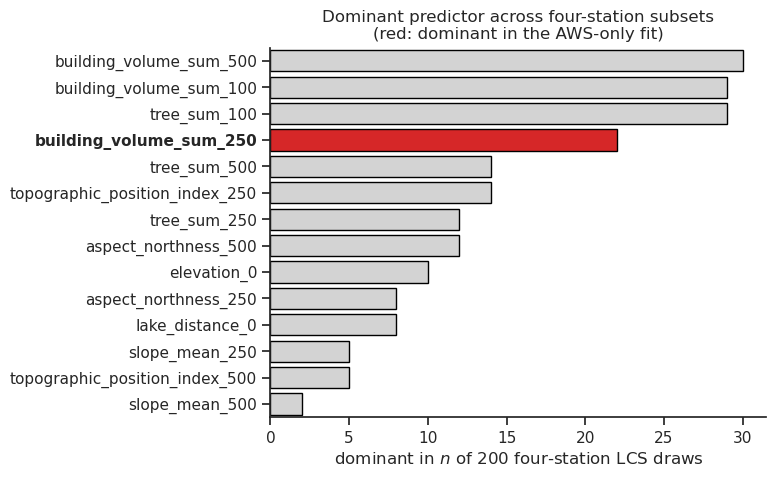

In [11]:
figwidth, figheight = plt.rcParams["figure.figsize"]

fig, ax = plt.subplots(figsize=(figwidth, figheight))
sns.countplot(
    y=dominant_ser,
    order=dominant_counts.index,
    color="lightgray",
    edgecolor="black",
    ax=ax,
)
# highlight the predictor that dominates the AWS-only fit
for tick_label, patch in zip(ax.get_yticklabels(), ax.patches):
    if tick_label.get_text() == aws_dominant:
        patch.set_facecolor("tab:red")
        tick_label.set_fontweight("bold")
ax.set_xlabel(f"dominant in $n$ of {n_draws} four-station LCS draws")
ax.set_ylabel("")
ax.set_title(
    "Dominant predictor across four-station subsets\n"
    "(red: dominant in the AWS-only fit)"
)
sns.despine(fig)

## Save results

In [12]:
control_df.to_csv(dst_control_filepath, index=False)